# Задача 4.1 — Выборка без возвращения

---

## 1. Условие

Корзина содержит 23 шара: 8 белых, 6 синих и 9 красных. На каждом шаге из корзины «наудачу» извлекается шар и назад в корзину не возвращается. Из корзины наудачу (без возвращения) извлечены 6 шаров. Найдите вероятности событий и покажите их статистическую устойчивость:

а) $A = \{\text{все шары красные}\}$;

б) $B = \{3 \text{ синих, } 2 \text{ белых и } 1 \text{ красный}\}$;

в) $D = \{\text{в точности } 4 \text{ белых шара}\}$;

г) разобрать случай извлечения шаров **с возвращением**. Найдите вероятность $P(A)$ события $A$, если «статистическая вероятность» равна $p^{\wedge}(A) \approx 0{,}00358549$.

---

## 2. Теоретическая часть

### Гипергеометрическая вероятность (без возвращения)

Число способов выбрать $k$ шаров данного цвета из $m$ имеющихся — $\binom{m}{k}$. Общее число способов выбрать 6 шаров из 23 — $\binom{23}{6}$. Тогда

$$
P = \frac{\binom{m_1}{k_1}\binom{m_2}{k_2}\binom{m_3}{k_3}}{\binom{23}{6}}.
$$

### Схема с возвращением (полиномиальное распределение)

При извлечении с возвращением вероятность получить $k_1$ белых, $k_2$ синих, $k_3$ красных шаров за $n=6$ извлечений:

$$
P = \frac{n!}{k_1!\,k_2!\,k_3!}\,p_1^{k_1}p_2^{k_2}p_3^{k_3},
$$

где $p_1 = \frac{8}{23}$, $p_2 = \frac{6}{23}$, $p_3 = \frac{9}{23}$.

### Статистическая устойчивость

Проводим $N$ реализаций опыта, считаем относительную частоту $p^{\wedge}(A) = \frac{N(A)}{N}$ и строим график её зависимости от $N$. При больших $N$ частота стабилизируется около теоретической вероятности.

---

## 3. Решение

P(A) = 0.0008321198252548
P(B) = 0.0499271895152902
P(D) = 0.0728104847097982


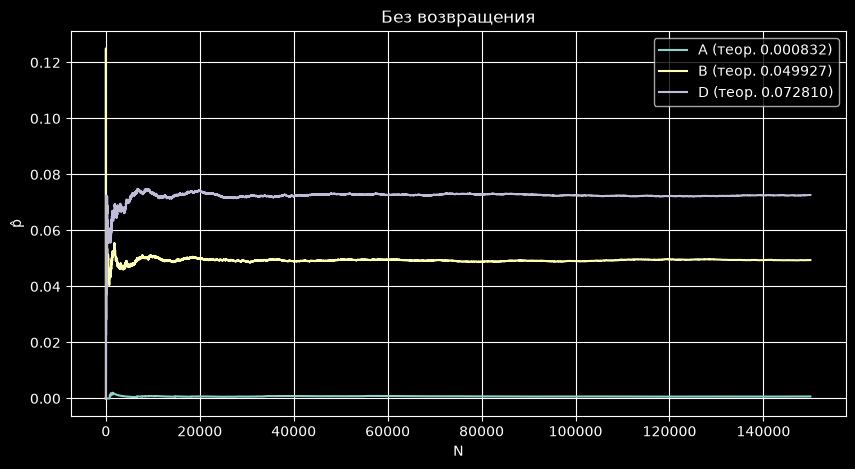


P(A) с возвращением (все красные) = 0.0035899470296693
Отношение p_stat / p_red^6 = 0.998758


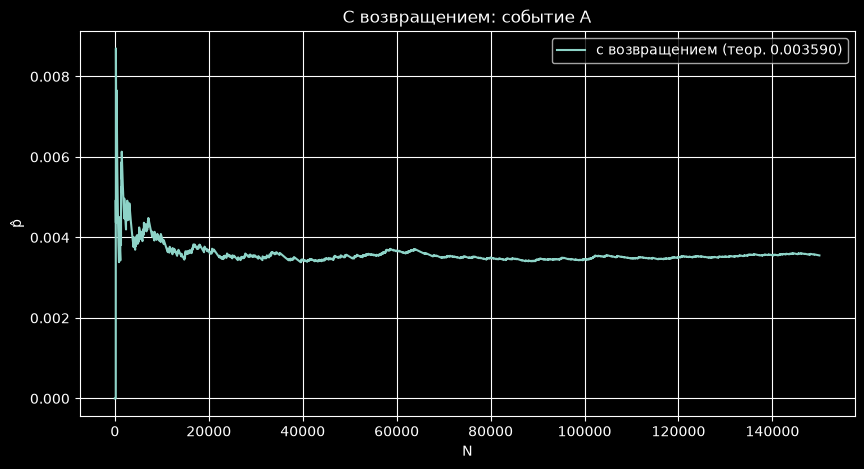

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from math import comb

N_total = comb(23, 6)

# а) все 6 шаров красные: C(9,6)
P_A = comb(9, 6) / N_total

# б) 3 синих, 2 белых, 1 красный: C(6,3)*C(8,2)*C(9,1)
P_B = comb(6, 3) * comb(8, 2) * comb(9, 1) / N_total

# в) ровно 4 белых: C(8,4)*C(15,2)
P_D = comb(8, 4) * comb(15, 2) / N_total

print(f"P(A) = {P_A:.16f}")
print(f"P(B) = {P_B:.16f}")
print(f"P(D) = {P_D:.16f}")

# ---------- Моделирование без возвращения ----------
def simulate_without_replacement(N, n_draw=6, seed=0):
    rng = np.random.default_rng(seed)
    balls = np.array([0]*8 + [1]*6 + [2]*9)  # 0-белый, 1-синий, 2-красный
    hits_A = np.zeros(N, dtype=int)
    hits_B = np.zeros(N, dtype=int)
    hits_D = np.zeros(N, dtype=int)
    for i in range(N):
        sample = rng.choice(balls, size=n_draw, replace=False)
        cnt = np.bincount(sample, minlength=3)
        hits_A[i] = (cnt[2] == 6)
        hits_B[i] = (cnt[1] == 3 and cnt[0] == 2 and cnt[2] == 1)
        hits_D[i] = (cnt[0] == 4)
    return hits_A, hits_B, hits_D

N = 150_000
hits_A, hits_B, hits_D = simulate_without_replacement(N, seed=42)

freq_A = np.cumsum(hits_A) / np.arange(1, N+1)
freq_B = np.cumsum(hits_B) / np.arange(1, N+1)
freq_D = np.cumsum(hits_D) / np.arange(1, N+1)

plt.figure(figsize=(10, 5))
plt.plot(freq_A, label=f"A (теор. {P_A:.6f})")
plt.plot(freq_B, label=f"B (теор. {P_B:.6f})")
plt.plot(freq_D, label=f"D (теор. {P_D:.6f})")
plt.xlabel("N"); plt.ylabel("p̂"); plt.legend(); plt.grid(True)
plt.title("Без возвращения")
plt.show()

# ---------- г) С возвращением ----------
p_white, p_blue, p_red = 8/23, 6/23, 9/23

def multinom_prob(n, k1, k2, k3):
    from math import factorial
    return factorial(n)/(factorial(k1)*factorial(k2)*factorial(k3)) * p_white**k1 * p_blue**k2 * p_red**k3

P_A_with_ret = multinom_prob(6, 0, 0, 6)   # все красные
print(f"\nP(A) с возвращением (все красные) = {P_A_with_ret:.16f}")

# Проверка по «статистической вероятности» 0.00358549:
p_stat = 0.00358549
print(f"Отношение p_stat / p_red^6 = {p_stat / p_red**6:.6f}")

# ---------- Моделирование с возвращением ----------
def simulate_with_replacement(N, n_draw=6, seed=1):
    rng = np.random.default_rng(seed)
    probs = [p_white, p_blue, p_red]
    hits = np.zeros(N, dtype=int)
    for i in range(N):
        sample = rng.choice(3, size=n_draw, p=probs)
        hits[i] = np.all(sample == 2)
    return hits

hits_ret = simulate_with_replacement(150_000, seed=7)
freq_ret = np.cumsum(hits_ret) / np.arange(1, 150_001)

plt.figure(figsize=(10, 5))
plt.plot(freq_ret, label=f"с возвращением (теор. {P_A_with_ret:.6f})")
plt.xlabel("N"); plt.ylabel("p̂"); plt.legend(); plt.grid(True)
plt.title("С возвращением: событие A")
plt.show()